# Can a computer predict BatChat's favorite Batman stories?

*Undone* ranks **47th** of the 740 Batman stories on BatChat. Our best model guesses somewhere near **500th**. It knows who made the comic and when it came out, but it has no idea how a silent issue about grief reads.

How much of BatChat's taste can a model learn from creators, dates, characters, and plot summaries?

**Rank 1 is best.** New to the data? Start with [Who gets the good Batman stories?](https://www.kaggle.com/code/danofer/who-gets-the-good-batman-stories) or [BatChat vs the crowd](https://www.kaggle.com/code/danofer/batchat-vs-the-crowd-where-batman-fans-disagree).

*By [Dan Ofer](https://scholar.google.com/citations?user=uDx2ItYAAAAJ) · [Dataset](https://www.kaggle.com/datasets/danofer/batchat-batman-rankings)*

In [1]:
from itertools import pairwise
from pathlib import Path
from textwrap import fill

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy.cluster.hierarchy import DisjointSet
from sklearn.compose import make_column_transformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import RidgeCV
from sklearn.metrics import mean_absolute_error
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Kaggle mounts the dataset under /kaggle/input; locally, `make share` stages it in data/kaggle.
DATA = next(
    p.parent
    for root in ["/kaggle/input", "data/kaggle", "../data/kaggle"]
    for p in Path(root).rglob("stories.csv")
)
sns.set_theme(
    style="ticks",
    font_scale=1.05,
    rc={
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titleweight": "bold",
        "axes.titlepad": 12,
        "figure.dpi": 120,
        "savefig.dpi": 200,
    },
)
BLUE, ORANGE, GREY = "#2767A0", "#D57927", "#75818C"

stories = pd.read_csv(DATA / "stories.csv").merge(
    pd.read_csv(DATA / "story_features.csv"), on="story_id", validate="one_to_one"
)
issues = pd.read_csv(DATA / "issues.csv")
texts = pd.read_csv(DATA / "story_texts.csv")
N = len(stories)
y = stories["rank"].to_numpy(dtype=float)
print(f"{N} ranked stories, from {stories.title[0]} (#1) to {stories.title[N - 1]} (#{N})")

740 ranked stories, from Year One (#1) to Batman: Three Jokers #1-3 (#740)


## Inputs

Publication year, issue count, discussion timing, format, selected-story credits, featured characters, antagonists, and creators' pre-publication Eisner wins. Names become presence indicators; missing metadata remains unknown.

Three example rows show the inputs below. `New Earth` and `Prime Earth` are continuity labels.

In [2]:
ROLES = ["writers", "pencilers", "inkers", "colorists", "letterers", "editors"]
NAMES = ["narrative_" + role for role in ROLES]
CAST = ["featured_entity_ids", "antagonists_entity_ids"]
WHEN = ["cover_year_start", "issue_count", "discussion_day"]
AWARDS = ["creator_eisner_personal_wins_pre_publication"]
TFIDF = dict(stop_words="english", min_df=3, max_df=0.9, sublinear_tf=True)

X = stories[
    ["medium", "format_hint", "cover_year_start", "issue_count", *NAMES, *CAST, *AWARDS]
].copy()
dates = pd.to_datetime(stories.discussion_date)
X["discussion_day"] = (dates - dates.min()).dt.days
X[NAMES + CAST] = X[NAMES + CAST].fillna("")


def model(numbers=(), name_lists=(), text=None, forest=False):
    """Numbers are scaled, format is one-hot encoded, every name in a list becomes a 0/1 column,
    and `text` (a column name) becomes TF-IDF word weights."""
    features = make_column_transformer(
        (make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), list(numbers)),
        (OneHotEncoder(handle_unknown="ignore", min_frequency=3), ["medium", "format_hint"]),
        *[
            (CountVectorizer(token_pattern=r"[^|]+", lowercase=False, binary=True, min_df=3), col)
            for col in name_lists
        ],
        *([(TfidfVectorizer(**TFIDF), text)] if text else []),
    )
    if forest:
        return make_pipeline(
            features,
            RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=42, n_jobs=-1),
        )
    return make_pipeline(features, RidgeCV(alphas=np.logspace(-1, 3, 9)))


X.head(3).T

,0,1,2
medium,comic,comic,comic
format_hint,unspecified,unspecified,unspecified
cover_year_start,1987.0,2000.0,2018.0
issue_count,4.0,1.0,3.0
narrative_writers,Frank Miller,Darwyn Cooke,Tom King
narrative_pencilers,Dave Mazzucchelli,Darwyn Cooke,Lee Weeks
narrative_inkers,Dave Mazzucchelli,Darwyn Cooke,Lee Weeks
narrative_colorists,Richmond Lewis,Darwyn Cooke,Elizabeth Breitweiser
narrative_letterers,Todd Klein,Jon Babcock,Clayton Cowles
narrative_editors,Dennis O'Neil,Mark Chiarello,Brittany Holzherr|Jamie S. Rich


## Can we beat guessing the middle?

Compare ridge regression and a random forest with a training-fold average baseline. Error is measured in rank places: a prediction of #200 for the story at #100 misses by 100.

<details><summary>Validation</summary>

Every prediction is held out. Five folds keep stories sharing an issue or episode together, preventing related readings from appearing on both sides of a split. Preprocessing is fitted within each training fold.

</details>

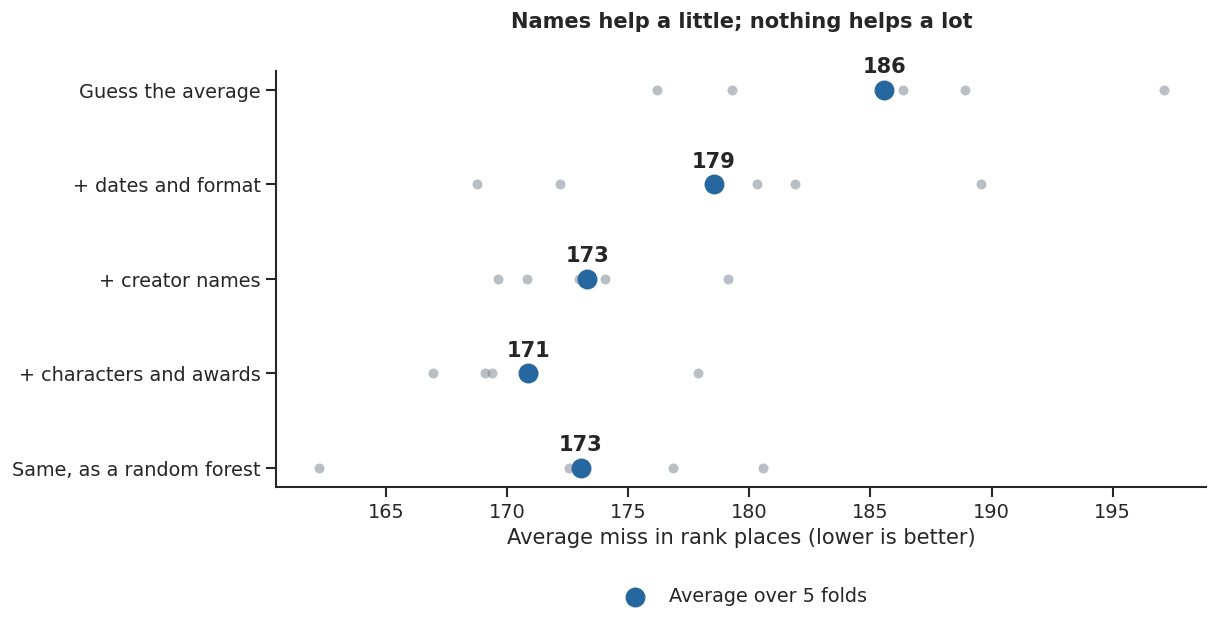

In [3]:
# Stories that share an issue or an episode stay in the same fold.
links = pd.concat(
    [
        pd.DataFrame({"story_id": stories.story_id, "key": "episode " + stories.episode_url}),
        pd.DataFrame(
            {"story_id": issues.story_id, "key": "issue " + issues.issue_id.astype("string")}
        ),
    ]
).dropna()
linked = DisjointSet(stories.story_id)
for _, ids in links.groupby("key").story_id:
    for a, b in pairwise(ids):
        linked.merge(a, b)
label = {story: min(group) for group in linked.subsets() for story in group}
groups = stories.story_id.map(label).to_numpy()
folds = list(GroupKFold(n_splits=5, shuffle=True, random_state=42).split(X, groups=groups))

ladder = {
    "Guess the average": DummyRegressor(),
    "+ dates and format": model(WHEN),
    "+ creator names": model(WHEN, NAMES),
    "+ characters and awards": model(WHEN + AWARDS, NAMES + CAST),
    "Same, as a random forest": model(WHEN + AWARDS, NAMES + CAST, forest=True),
}
predictions = {name: cross_val_predict(m, X, y, cv=folds) for name, m in ladder.items()}
fold_errors = pd.DataFrame(
    {
        name: [mean_absolute_error(y[test], p[test]) for _, test in folds]
        for name, p in predictions.items()
    }
).melt(var_name="model", value_name="error")
errors = fold_errors.groupby("model", sort=False).error.mean()

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.stripplot(
    data=fold_errors, x="error", y="model", color=GREY, alpha=0.5, size=6, jitter=False, ax=ax
)
ax.scatter(errors, range(len(errors)), color=BLUE, s=120, zorder=3, label="Average over 5 folds")
for pos, value in enumerate(errors):
    ax.annotate(
        f"{value:.0f}",
        (value, pos),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center",
        fontweight="bold",
    )
ax.set(
    xlabel="Average miss in rank places (lower is better)",
    ylabel="",
    title="Names help a little; nothing helps a lot\n",
)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), frameon=False)
plt.show()

The models reduce error by roughly **8%**, but still miss by about **170 rank places**. Fold-to-fold variation is large relative to the smaller gains between feature sets.

Below: actual rank across, held-out prediction up. Each dot is one story.

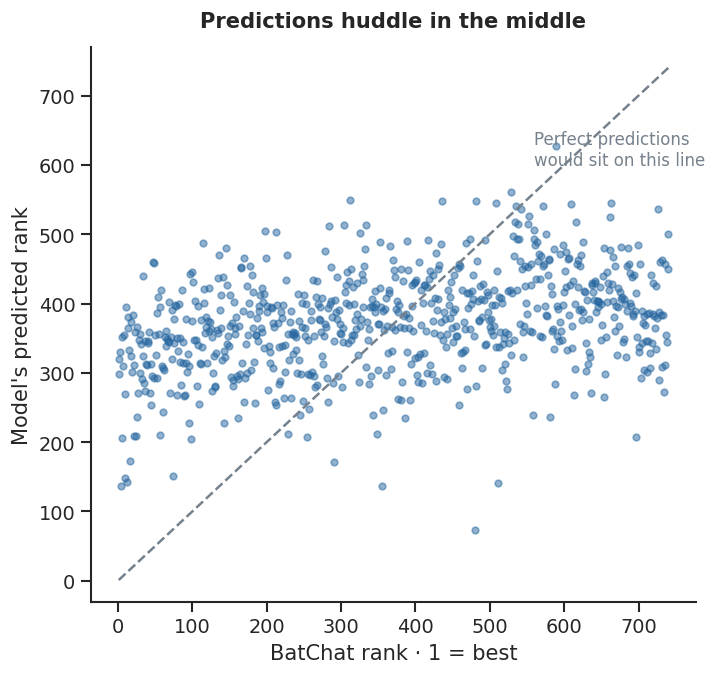

In [4]:
best = "+ characters and awards"
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(y, predictions[best], s=16, alpha=0.5, color=BLUE)
ax.plot([1, N], [1, N], ls="--", color=GREY)
ax.annotate("Perfect predictions\nwould sit on this line", (560, 600), color=GREY, fontsize=10)
ax.set(
    xlabel="BatChat rank · 1 = best",
    ylabel="Model's predicted rank",
    ylim=(-30, N + 30),  # one wild guess below −200 is left off the chart
    title="Predictions huddle in the middle",
)
plt.show()

Predictions pull the extremes toward the middle. Shared creators and dates leave plenty of room for different reading experiences.

## What about an unseen artist?

For each of the five busiest pencilers, remove all their stories from training and predict them together.

In [5]:
rows = []
names = X[NAMES].apply(lambda col: col.str.split("|").map(set))
artists = names.narrative_pencilers.explode().value_counts().head(5).index
for artist in artists:
    involved = names.apply(lambda col: col.map(lambda s: artist in s)).any(axis=1)
    test = names.narrative_pencilers.map(lambda s: artist in s).to_numpy()
    train = (~involved & ~pd.Series(groups).isin(groups[test])).to_numpy()
    fitted = ladder[best].fit(X[train], y[train])
    rows.append(
        {
            "Artist": artist,
            "Stories": test.sum(),
            "Their median rank": np.median(y[test]),
            "Model's miss (rank places)": mean_absolute_error(y[test], fitted.predict(X[test])),
            "Average-guess miss (rank places)": mean_absolute_error(
                y[test], np.full(test.sum(), y[train].mean())
            ),
        }
    )
pd.DataFrame(rows).set_index("Artist").round(0)

,Stories,Their median rank,Model's miss (rank places),Average-guess miss (rank places)
Artist,,,,
Jim Aparo,24,364.0,157.0,169.0
Bob Kane,20,544.0,139.0,190.0
Norm Breyfogle,19,324.0,138.0,140.0
Kelley Jones,16,312.0,214.0,212.0
Neal Adams,16,398.0,163.0,173.0


Bob Kane's stories are easier for this model than Kelley Jones's. Jones's books span *Red Rain* (#6) to *Unseen* (#716), despite sharing a writer and artist.

## The interesting misses

The two models disagree most with these rankings in the same direction. These are starting points for a reading comparison; the [reranking notebook](https://www.kaggle.com/code/danofer/which-batman-stories-deserve-a-second-look) examines twenty cases.

In [6]:
misses = stories[["title", "rank"]].assign(
    ridge=predictions[best].round(), forest=predictions["Same, as a random forest"].round()
)
misses["surprise"] = misses.ridge - misses["rank"]
both_agree = np.sign(misses.surprise) == np.sign(misses.forest - misses["rank"])
columns = {
    "title": "Story",
    "rank": "BatChat rank",
    "ridge": "Model guessed",
    "forest": "Forest guessed",
}
for caption, pick in [
    ("The hosts liked these far more than the metadata suggests:", misses[both_agree].nlargest),
    ("…and these far less:", misses[both_agree].nsmallest),
]:
    print(caption)
    display(pick(8, "surprise")[list(columns)].rename(columns=columns).set_index("Story"))

The hosts liked these far more than the metadata suggests:


,BatChat rank,Model guessed,Forest guessed
Story,,,
Undone,47,460.0,505.0
Night of the Stalker,48,459.0,466.0
The Dark Knight Returns: The Last Crusade,33,440.0,395.0
The Joker’s Five-Way Revenge,11,395.0,411.0
The Joker/ The Joker Returns,114,488.0,526.0
Kingdom Come #1-4,13,381.0,327.0
The Garden of Earthly Delights,20,384.0,352.0
There is Hope in Crime Alley,58,419.0,438.0


…and these far less:


,BatChat rank,Model guessed,Forest guessed
Story,,,
Knightquest: The Search,697,208.0,306.0
Batman: White Knight #1-8,734,272.0,285.0
Batman/Green Arrow: The Poison Tomorrow,727,290.0,282.0
Superman and Batman Vs. Vampires and Werewolves,732,308.0,292.0
Odyssey,735,311.0,381.0
The Wedding,703,292.0,367.0
The Last Batman Story–?,711,302.0,341.0
Batman: Unseen #1-5,716,307.0,326.0


*White Knight* (#734), *Unseen*, and *Knightquest: The Search* sit well below their predictions. Familiar credits do not explain the hosts' response to each book.

## Does the plot help?

The wiki summaries contain roughly **700,000 words**. TF-IDF weights recurring, distinctive terms, but discards word order and images. About a fifth of stories have no usable summary, with recent comics especially underrepresented.

In [7]:
available = texts[texts.text_status.eq("available")].drop_duplicates(["story_id", "synopsis_text"])
X["plot_text"] = stories.story_id.map(
    available.groupby("story_id").synopsis_text.agg(" ".join)
).fillna("")
X["has_plot"] = X.plot_text.ne("").astype(float)
plot_ladder = {
    "Plot words only": model(text="plot_text"),
    "Names, dates, cast and awards": model(WHEN + AWARDS + ["has_plot"], NAMES + CAST),
    "… plus plot words": model(WHEN + AWARDS + ["has_plot"], NAMES + CAST, text="plot_text"),
}
plot_scores = pd.Series(
    {"Guess the average": errors["Guess the average"]}
    | {
        name: mean_absolute_error(y, cross_val_predict(m, X, y, cv=folds))
        for name, m in plot_ladder.items()
    },
    name="Average miss (rank places)",
)
plot_scores.round(1).to_frame()

,Average miss (rank places)
Guess the average,185.6
Plot words only,178.9
"Names, dates, cast and awards",170.9
… plus plot words,171.6


Words alone beat the average-rank baseline. Adding them to names, dates and cast brings little further improvement in this comparison.

## Better for finding related stories?

For *Undone*, *Ego*, and *The Clown at Midnight*, find the story with the closest word profile. Stories sharing an episode or issue are excluded. Blue is the query, orange its match; the words on the right contribute most to their similarity.

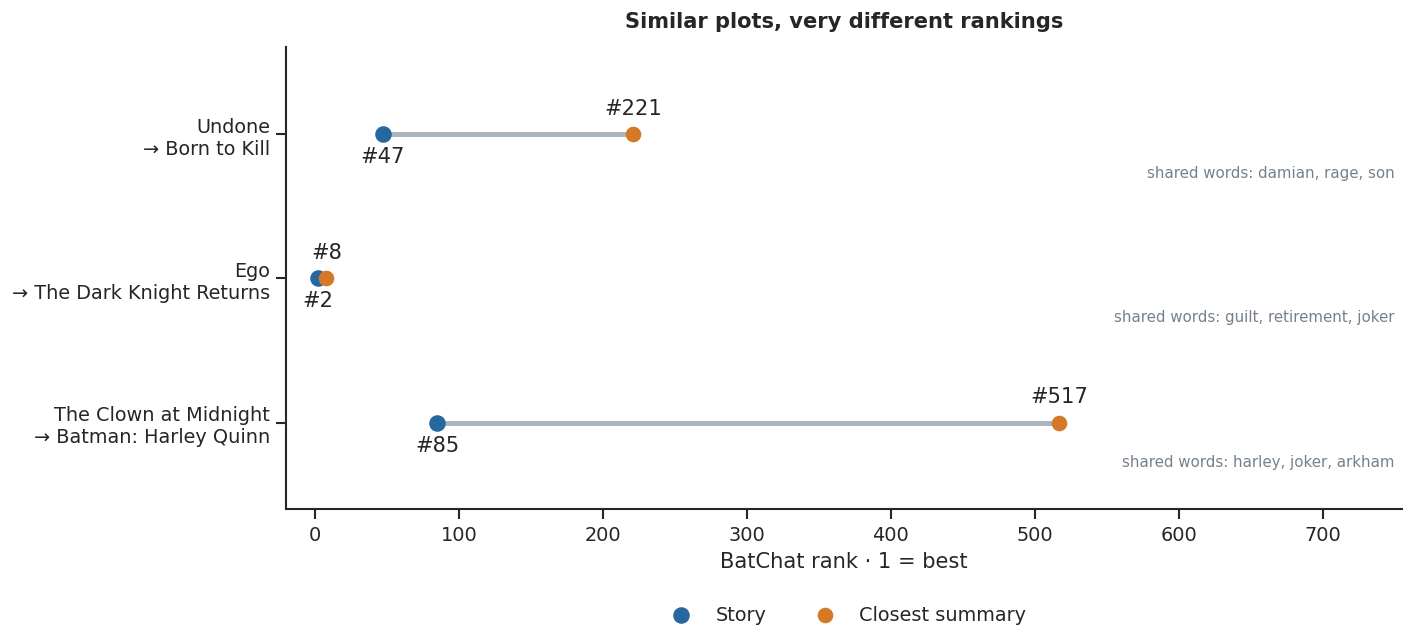

In [8]:
has_text = np.flatnonzero(X.plot_text.str.split().str.len().ge(200))
words = TfidfVectorizer(**TFIDF)
vectors = words.fit_transform(X.plot_text.iloc[has_text])
similarity = cosine_similarity(vectors)
pairs = []
for title in ["Undone", "Ego", "The Clown at Midnight"]:
    i = int(np.flatnonzero(stories.title.iloc[has_text].eq(title))[0])
    scores = np.where(groups[has_text] == groups[has_text[i]], -1, similarity[i])
    j = int(scores.argmax())
    shared = vectors[i].multiply(vectors[j]).toarray().ravel()
    pairs.append(
        {
            "story": title,
            "story_rank": int(y[has_text[i]]),
            "closest": stories.title.iloc[has_text[j]],
            "closest_rank": int(y[has_text[j]]),
            "shared_words": ", ".join(words.get_feature_names_out()[np.argsort(-shared)[:3]]),
        }
    )
pairs = pd.DataFrame(pairs)

fig, ax = plt.subplots(figsize=(12, 5))
for pos, row in pairs.iterrows():
    ax.plot([row.story_rank, row.closest_rank], [pos, pos], color="#ABB5BD", lw=3, zorder=1)
    ax.annotate(
        f"#{row.story_rank}",
        (row.story_rank, pos),
        xytext=(0, -17),
        textcoords="offset points",
        ha="center",
    )
    ax.annotate(
        f"#{row.closest_rank}",
        (row.closest_rank, pos),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center",
    )
    ax.text(
        N + 10, pos + 0.3, f"shared words: {row.shared_words}", ha="right", fontsize=9, color=GREY
    )
ax.scatter(pairs.story_rank, pairs.index, color=BLUE, s=80, zorder=3, label="Story")
ax.scatter(pairs.closest_rank, pairs.index, color=ORANGE, s=70, zorder=3, label="Closest summary")
ax.set(
    yticks=pairs.index,
    yticklabels=[fill(r.story, 25) + "\n→ " + fill(r.closest, 25) for r in pairs.itertuples()],
    xlim=(-20, N + 15),
    ylim=(len(pairs) - 0.4, -0.6),
    xlabel="BatChat rank · 1 = best",
    title="Similar plots, very different rankings",
)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2, frameon=False)
plt.show()

*Undone* and *Born to Kill* share **Damian, rage, and son**, despite ranking #47 and #221. **Guilt, retirement, and Joker** link *Ego* (#2) with *The Dark Knight Returns* (#8).

Names and dates offer modest predictive value; summaries are useful for finding comparisons. The large residuals show what these inputs leave unexplained.

Read next: [Twenty reranking cases](https://www.kaggle.com/code/danofer/which-batman-stories-deserve-a-second-look) · [Feature effects and support](https://www.kaggle.com/code/danofer/what-pushes-a-batman-story-up-batchat-s-list)